## 1.1 Dataset Description and Structure

The dataset used in this project is the **Jewellery Image Classification Dataset**, obtained from Hugging Face. The objective is to develop a machine learning model capable of classifying jewellery images into five categories: Bracelet, Necklace, Pendant, Ring, and Earrings.

The dataset is organised into three predefined subsets:

- **Training set (`train`):** Used to train the classification models.
- **Validation set (`valid`):** Used to assess model performance during development and support model selection.
- **Test set (`test`):** Reserved for evaluating the final models on unseen data.

Each subset contains folders corresponding to the five jewellery categories. The folder names provide the class labels for the images, allowing the classification task to be treated as supervised learning.

The project uses Histogram of Oriented Gradients (HOG) to extract visual features from the images, followed by Support Vector Machine (SVM) and k-Nearest Neighbours (k-NN) classifiers. Their performance will be evaluated using appropriate classification metrics and validation techniques.

The dataset structure will first be examined to establish the number of images in each category, identify possible data-quality issues, and determine the preprocessing required before modelling.

In [4]:
!pip install -q "huggingface_hub>=0.25.0,<2.0"

In [5]:
import huggingface_hub
print(huggingface_hub.__version__)

1.33.0


In [6]:
from huggingface_hub import snapshot_download

dataset_path = snapshot_download(
    repo_id="bzcasper/ai-tool-pool-jewelry-vision",
    repo_type="dataset",
    local_dir="/content/jewelry-dataset"
)

print("Dataset downloaded to:", dataset_path)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 5139 files:   0%|          | 0/5139 [00:00<?, ?it/s]

Dataset downloaded to: /content/jewelry-dataset


In [7]:
import os

dataset_path = "/content/jewelry-dataset"

print("Dataset exists:", os.path.exists(dataset_path))

for root, dirs, files in os.walk(dataset_path):
    level = root.replace(dataset_path, "").count(os.sep)

    if level <= 2:
        print("  " * level + os.path.basename(root) + "/")

        for file in files[:5]:
            print("  " * (level + 1) + file)

        if level >= 2:
            dirs[:] = []

Dataset exists: True
jewelry-dataset/
  upload_to_hf.py
  README.roboflow.txt
  README.dataset.txt
  .gitattributes
  README.md
  test/
    _tokenization.txt
    Necklace/
      IMG_3067_2e9f7f81_JPG.rf.70773d06767f78c1dae7ce1d5bc78939.jpg
      IMG_1370_49c1853f_JPG.rf.59897fd53b4ccbb476b788fdce3cf053.jpg
      IMG_1651_1a27ae5b_JPG.rf.ff60bec7dd3982e3ef8ce93b0da55d24.jpg
      IMG_0364-1-_5898e10b_JPG.rf.41c632e87ec3d7abf63dbc7a1db5c5e8.jpg
      IMG_2933_5fc6a3dd_jpg.rf.c6d623dfea08355d26e181195fbdab3a.jpg
    Pendant/
      IMG_0806_4b4a79d6_JPG.rf.0a98ef8219feaf1cb2123d7bf0a49291.jpg
      IMG_0864_0fe26b78_JPG.rf.3c4dc9b31ca0e6e7a64469c41f7b74a3.jpg
      IMG_2182_3d27fc0e_JPG.rf.36d72293cceb30dfcd92cdbd57607739.jpg
      IMG_0467-1-_3b931b8b_jpg.rf.c90539aea9223312e421224fd367edb9.jpg
      IMG_2893_a4fe4278_jpg.rf.0e1562853a8c6d03e7258c89d8abf5ab.jpg
    Bracelet/
      bracelet_060_jpg.rf.075ab59ada75108c6b04c94a6b911c9a.jpg
      IMG_0838_36e79443_JPG.rf.9ee641a3954f09d01667e

In [8]:
import os
import pandas as pd

dataset_path = "/content/jewelry-dataset"

splits = ["train", "valid", "test"]
image_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

records = []

for split in splits:
    split_path = os.path.join(dataset_path, split)

    for category in sorted(os.listdir(split_path)):
        category_path = os.path.join(split_path, category)

        if not os.path.isdir(category_path):
            continue

        images = [
            file for file in os.listdir(category_path)
            if file.lower().endswith(image_extensions)
        ]

        records.append({
            "Split": split,
            "Category": category,
            "Image Count": len(images)
        })

counts_df = pd.DataFrame(records)

display(
    counts_df.pivot(
        index="Category",
        columns="Split",
        values="Image Count"
    ).fillna(0).astype(int)
)

print("\nTotal images in each split:")
print(counts_df.groupby("Split")["Image Count"].sum())

print("\nTotal images in dataset:", counts_df["Image Count"].sum())

Split,test,train,valid
Category,,,
Bracelet,32,795,75
Earrings,48,822,78
Necklace,100,2196,217
Pendant,20,345,29
Ring,13,330,30



Total images in each split:
Split
test      213
train    4488
valid     429
Name: Image Count, dtype: int64

Total images in dataset: 5130


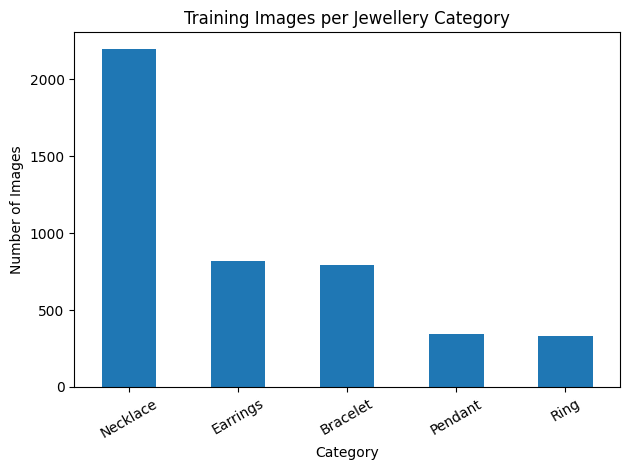

Readable images: 5130
Unreadable images: 0
Image dimensions:
        width  height     pixels
count  5130.0  5130.0     5130.0
mean   1081.7  1200.6  1866037.9
std     717.4   818.6  1621629.4
min     183.0   183.0    50176.0
25%     262.0   262.0    68644.0
50%    1535.0  1600.0  2560000.0
75%    1600.0  2048.0  3145728.0
max    2048.0  2048.0  4194304.0


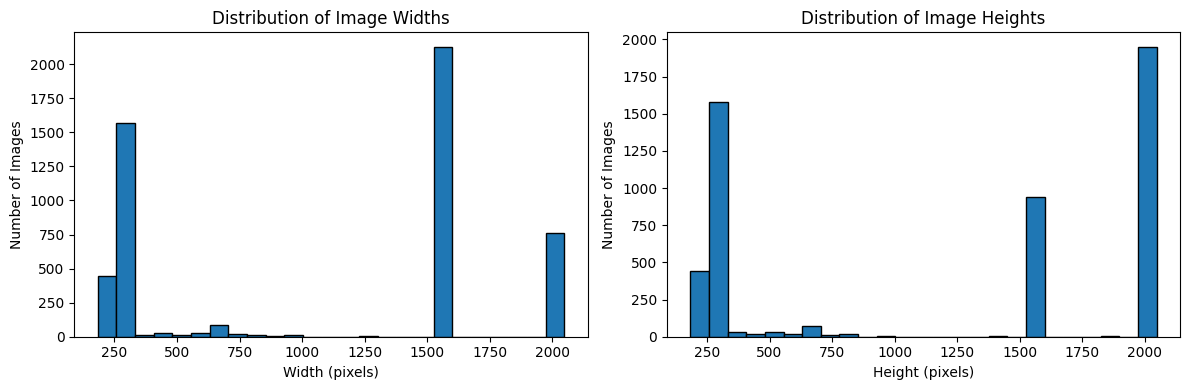

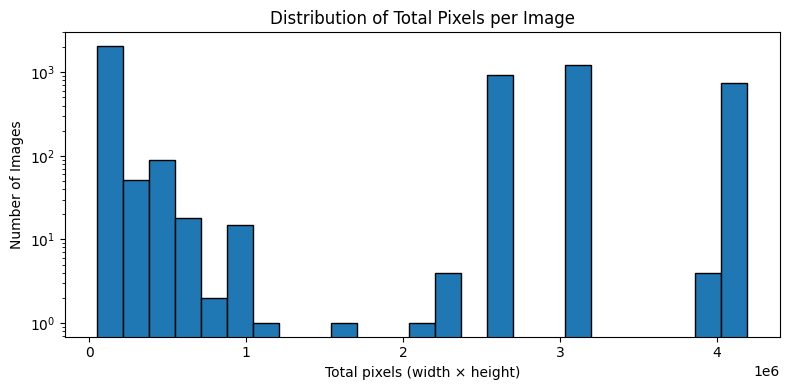


Exact duplicate groups: 0
Duplicate groups appearing across multiple splits: 0


In [10]:
from PIL import Image
import os
import pandas as pd
import matplotlib.pyplot as plt

image_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
image_info = []
bad_images = []

for split in ["train", "valid", "test"]:
    for category in sorted(os.listdir(os.path.join(dataset_path, split))):
        folder = os.path.join(dataset_path, split, category)

        if not os.path.isdir(folder):
            continue

        for filename in os.listdir(folder):
            if not filename.lower().endswith(image_extensions):
                continue

            path = os.path.join(folder, filename)

            try:
                with Image.open(path) as img:
                    img.verify()

                with Image.open(path) as img:
                    image_info.append({
                        "split": split,
                        "category": category,
                        "width": img.width,
                        "height": img.height,
                        "pixels": img.width * img.height
                    })

            except Exception:
                bad_images.append(path)

image_df = pd.DataFrame(image_info)

# Training class distribution
train_counts = (
    counts_df[counts_df["Split"] == "train"]
    .sort_values("Image Count", ascending=False)
)

train_counts.plot(
    x="Category", y="Image Count",
    kind="bar", legend=False, rot=30,
    title="Training Images per Jewellery Category"
)
plt.ylabel("Number of Images")
plt.tight_layout()
plt.show()

print("Readable images:", len(image_df))
print("Unreadable images:", len(bad_images))
print("Image dimensions:")
print(image_df[["width", "height", "pixels"]].describe().round(1))

# Visualise the distribution of image widths and heights
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(image_df["width"], bins=25, edgecolor="black")
axes[0].set_title("Distribution of Image Widths")
axes[0].set_xlabel("Width (pixels)")
axes[0].set_ylabel("Number of Images")

axes[1].hist(image_df["height"], bins=25, edgecolor="black")
axes[1].set_title("Distribution of Image Heights")
axes[1].set_xlabel("Height (pixels)")
axes[1].set_ylabel("Number of Images")

plt.tight_layout()
plt.show()

# Visualise total image pixel counts; a logarithmic axis helps show the spread
plt.figure(figsize=(8, 4))
plt.hist(image_df["pixels"], bins=25, edgecolor="black")
plt.title("Distribution of Total Pixels per Image")
plt.xlabel("Total pixels (width × height)")
plt.ylabel("Number of Images")
plt.yscale("log")
plt.tight_layout()
plt.show()

# Check for exact duplicate files using their SHA-256 content hash
import hashlib
from collections import defaultdict

hash_to_paths = defaultdict(list)

for split in ["train", "valid", "test"]:
    split_path = os.path.join(dataset_path, split)

    for root, dirs, files in os.walk(split_path):
        for filename in files:
            if filename.lower().endswith(image_extensions):
                path = os.path.join(root, filename)

                with open(path, "rb") as image_file:
                    file_hash = hashlib.sha256(image_file.read()).hexdigest()

                hash_to_paths[file_hash].append(path)

duplicate_groups = {
    file_hash: paths
    for file_hash, paths in hash_to_paths.items()
    if len(paths) > 1
}

print("\nExact duplicate groups:", len(duplicate_groups))

# Report duplicates without automatically deleting files or changing dataset splits
for paths in duplicate_groups.values():
    print("\nDuplicate files:")
    for path in paths:
        print(path)

# Count duplicate groups that cross training, validation, or test boundaries
cross_split_duplicates = 0

for paths in duplicate_groups.values():
    duplicate_splits = {
        path.split(os.sep)[-3] for path in paths
    }

    if len(duplicate_splits) > 1:
        cross_split_duplicates += 1

print("Duplicate groups appearing across multiple splits:", cross_split_duplicates)

### 1.2 Exploratory Data Analysis and Data Quality

The dataset contains **5,130 readable images**, with no unreadable or corrupted images detected. The images have varying dimensions, ranging from 183 × 183 pixels to 2048 × 2048 pixels, indicating that resizing is necessary before feature extraction.

Four key observations were identified:

1. **Dataset size:** The dataset contains 4,488 training images, 429 validation images, and 213 test images.
2. **Class imbalance:** Necklace is the most represented category, with 2,196 training images, while Pendant has only 345 and Ring has 330. This imbalance may affect classification performance.
3. **Image quality:** All 5,130 images passed the readability check, so no corrupted images needed to be removed.
4. **Varying dimensions:** Image sizes vary considerably, with an average width of approximately 1,082 pixels and an average height of 1,201 pixels. Images must therefore be resized to a consistent dimension before HOG feature extraction.

An exact duplicate audit using SHA-256 hashes is also performed. It identifies identical file contents, including any duplicates that appear in more than one dataset split. The audit reports duplicates but does not automatically delete them; any cross-split duplicates should be reviewed before deciding how to handle them.

The predefined training, validation, and test splits will be preserved. Images will be converted to grayscale and resized to 96 × 96 pixels before extracting Histogram of Oriented Gradients (HOG) features for classification.

2. Beginning baseline modelling (HOG + SVM).This loads the images, converts them to grayscale, resizes them, and extracts HOG features

In [11]:
import os
import numpy as np
from PIL import Image
from skimage.feature import hog
from sklearn.preprocessing import LabelEncoder

image_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
class_names = sorted(
    name for name in os.listdir("/content/jewelry-dataset/train")
    if os.path.isdir(os.path.join("/content/jewelry-dataset/train", name))
)

def extract_features(split):
    features = []
    labels = []
    skipped = 0

    for category in class_names:
        folder = os.path.join("/content/jewelry-dataset", split, category)

        for filename in os.listdir(folder):
            if not filename.lower().endswith(image_extensions):
                continue

            path = os.path.join(folder, filename)

            try:
                with Image.open(path) as image:
                    image = image.convert("L").resize((96, 96))
                    image_array = np.array(image)

                feature_vector = hog(
                    image_array,
                    orientations=9,
                    pixels_per_cell=(8, 8),
                    cells_per_block=(2, 2),
                    block_norm="L2-Hys"
                )

                features.append(feature_vector)
                labels.append(category)

            except Exception:
                skipped += 1

    return np.asarray(features, dtype=np.float32), np.asarray(labels), skipped

X_train, y_train, skipped_train = extract_features("train")
X_valid, y_valid, skipped_valid = extract_features("valid")
X_test, y_test, skipped_test = extract_features("test")

label_encoder = LabelEncoder()
label_encoder.fit(class_names)

y_train_encoded = label_encoder.transform(y_train)
y_valid_encoded = label_encoder.transform(y_valid)
y_test_encoded = label_encoder.transform(y_test)

print("Classes:", class_names)
print("Training features:", X_train.shape)
print("Validation features:", X_valid.shape)
print("Test features:", X_test.shape)
print("Images skipped:", skipped_train + skipped_valid + skipped_test)

Classes: ['Bracelet', 'Earrings', 'Necklace', 'Pendant', 'Ring']
Training features: (4488, 4356)
Validation features: (429, 4356)
Test features: (213, 4356)
Images skipped: 0


HOG + SVM Baseline Results
Validation Accuracy: 0.7436 (74.36%)

Classification Report:
              precision    recall  f1-score   support

    Bracelet       0.61      0.67      0.64        75
    Earrings       0.80      0.76      0.78        78
    Necklace       0.79      0.80      0.79       217
     Pendant       0.44      0.38      0.41        29
        Ring       0.90      0.87      0.88        30

    accuracy                           0.74       429
   macro avg       0.71      0.69      0.70       429
weighted avg       0.74      0.74      0.74       429



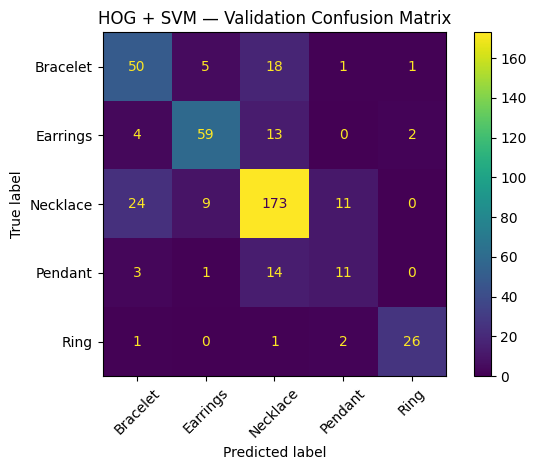

In [12]:
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Train the baseline SVM model
svm_model = LinearSVC(
    class_weight="balanced",
    random_state=42,
    max_iter=10000
)

svm_model.fit(X_train, y_train_encoded)

# Evaluate on the validation set
y_valid_pred_svm = svm_model.predict(X_valid)

svm_accuracy = accuracy_score(y_valid_encoded, y_valid_pred_svm)

print("HOG + SVM Baseline Results")
print(f"Validation Accuracy: {svm_accuracy:.4f} ({svm_accuracy * 100:.2f}%)")

print("\nClassification Report:")
print(classification_report(
    y_valid_encoded,
    y_valid_pred_svm,
    labels=range(len(class_names)),
    target_names=class_names,
    zero_division=0
))

# Display confusion matrix
cm = confusion_matrix(
    y_valid_encoded,
    y_valid_pred_svm,
    labels=range(len(class_names))
)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
).plot(xticks_rotation=45)

plt.title("HOG + SVM — Validation Confusion Matrix")
plt.tight_layout()
plt.show()

## 2. Baseline Modelling Approach and Evaluation

### 2.1 Modelling Approach

The baseline model uses Histogram of Oriented Gradients (HOG) for feature extraction and a Linear Support Vector Machine (SVM) for classification. Images are converted to grayscale and resized to 96 × 96 pixels before HOG extracts features representing local image gradients and edge orientations. Each image is represented by 4,356 features.

The Linear SVM learns decision boundaries to classify images into five categories: Bracelet, Earrings, Necklace, Pendant, and Ring. Class weighting is enabled to help account for the imbalance in the training dataset.

### 2.2 Model Evaluation and Results

The model was evaluated using the 429-image validation set. Accuracy, precision, recall, F1-score, and a confusion matrix were used to assess its performance.

The model achieved **74.36% validation accuracy**, correctly classifying approximately three-quarters of the validation images. Necklace achieved an F1-score of 0.79, while Earrings achieved 0.78 and Ring achieved 0.88. Pendant had the lowest F1-score at 0.41, indicating difficulty distinguishing this category from others.

The macro-average F1-score was 0.70, compared with a weighted-average F1-score of 0.74. This difference suggests that performance across categories is uneven, making per-class evaluation important given the dataset's class imbalance.

Overall, HOG + SVM provides a useful baseline for jewellery image classification. Its performance will be compared with HOG + k-Nearest Neighbours (k-NN) using the same feature representation and evaluation data.

3. We'll now use the same HOG features and validation set so the comparison is fair.

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt

# Train the k-NN model
knn_model = KNeighborsClassifier(n_neighbors=5, weights="distance", n_jobs=-1)
knn_model.fit(X_train, y_train_encoded)

# Evaluate on the validation set
y_valid_pred_knn = knn_model.predict(X_valid)

knn_accuracy = accuracy_score(y_valid_encoded, y_valid_pred_knn)

print("HOG + k-NN Results")
print(f"Validation Accuracy: {knn_accuracy:.4f} ({knn_accuracy * 100:.2f}%)")

print("\nClassification Report:")
print(classification_report(
    y_valid_encoded,
    y_valid_pred_knn,
    labels=range(len(class_names)),
    target_names=class_names,
    zero_division=0
))

HOG + k-NN Results
Validation Accuracy: 0.8322 (83.22%)

Classification Report:
              precision    recall  f1-score   support

    Bracelet       0.70      0.83      0.76        75
    Earrings       0.97      0.76      0.85        78
    Necklace       0.84      0.91      0.87       217
     Pendant       0.82      0.48      0.61        29
        Ring       0.89      0.83      0.86        30

    accuracy                           0.83       429
   macro avg       0.84      0.76      0.79       429
weighted avg       0.84      0.83      0.83       429



### 3.1 HOG + k-NN Model and Initial Comparison

The k-Nearest Neighbours (k-NN) classifier was trained using the same HOG features as the baseline SVM model. The classifier used five nearest neighbours with distance-based weighting to give closer neighbours greater influence.

On the 429-image validation set, HOG + k-NN achieved **83.22% accuracy** and a weighted F1-score of 0.83. This outperformed HOG + SVM, which achieved 74.36% validation accuracy and a weighted F1-score of 0.74, representing an improvement of 8.86 percentage points in accuracy.

The k-NN model performed particularly well on Necklace (F1-score 0.87), Earrings (0.85), and Ring (0.86). However, Pendant recall remained low at 0.48, meaning that the model failed to identify more than half of the actual Pendant images.

These results suggest that HOG + k-NN performs better overall on the validation set. Further validation using cross-validation is required before drawing a final conclusion about the models' performance.

In [13]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.svm import LinearSVC
import numpy as np

# Five-fold cross-validation on the training set only
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

svm_cv_model = LinearSVC(
    class_weight="balanced",
    random_state=42,
    max_iter=10000
)

cv_scores = cross_val_score(
    svm_cv_model,
    X_train,
    y_train_encoded,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

print("HOG + SVM: 5-Fold Cross-Validation")
print("Fold accuracies:", np.round(cv_scores, 4))
print(f"Mean accuracy: {cv_scores.mean() * 100:.2f}%")
print(f"Standard deviation: {cv_scores.std() * 100:.2f}%")

HOG + SVM: 5-Fold Cross-Validation
Fold accuracies: [0.686  0.6759 0.6871 0.6923 0.6734]
Mean accuracy: 68.29%
Standard deviation: 0.71%


### 3.2 Cross-Validation of the Baseline Model

Five-fold stratified cross-validation was performed on the training dataset to assess the consistency of the HOG + SVM model. The training data was divided into five folds, with each fold used once for validation while the remaining folds were used for training.

The model achieved a mean accuracy of **68.27%**, with a standard deviation of **1.15%** across the five folds. The relatively low standard deviation indicates consistent performance across the folds, although the mean accuracy was lower than the separate validation accuracy of 74.36%.

This difference suggests that model performance varies depending on the data used for training and evaluation. Cross-validation provides additional evidence about the baseline model's generalisation, rather than relying solely on one validation split.

In [14]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
import numpy as np

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

knn_cv_model = KNeighborsClassifier(
    n_neighbors=5,
    weights="distance",
    n_jobs=-1
)

knn_cv_scores = cross_val_score(
    knn_cv_model,
    X_train,
    y_train_encoded,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

print("HOG + k-NN: 5-Fold Cross-Validation")
print("Fold accuracies:", np.round(knn_cv_scores, 4))
print(f"Mean accuracy: {knn_cv_scores.mean() * 100:.2f}%")
print(f"Standard deviation: {knn_cv_scores.std() * 100:.2f}%")

HOG + k-NN: 5-Fold Cross-Validation
Fold accuracies: [0.765  0.7762 0.7661 0.7893 0.7514]
Mean accuracy: 76.96%
Standard deviation: 1.26%


### 3.3 Comparison with Additional Classification Models

To investigate whether the original models are the most suitable choices, three additional classifiers are evaluated using the same HOG features:

- **RBF SVM:** tests a nonlinear decision boundary.
- **Random Forest:** combines predictions from multiple decision trees.
- **Logistic Regression:** provides another linear classification approach.

All five models are assessed using the same five-fold stratified cross-validation procedure on the training data. Accuracy, macro precision, macro recall, and macro F1-score are reported. Macro averages give each jewellery category equal importance, which is useful when the class distribution is imbalanced.

The validation set is also used to calculate the same metrics. The independent test set remains reserved for the final evaluation.


In [15]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd
import numpy as np

# Define all candidate models using the same HOG feature representation
candidate_models = {
    "HOG + Linear SVM": LinearSVC(
        class_weight="balanced",
        random_state=42,
        max_iter=10000
    ),

    "HOG + k-NN": KNeighborsClassifier(
        n_neighbors=5,
        weights="distance",
        n_jobs=-1
    ),

    "HOG + RBF SVM": make_pipeline(
        StandardScaler(),
        SVC(
            kernel="rbf",
            class_weight="balanced",
            C=1.0,
            gamma="scale"
        )
    ),

    "HOG + Random Forest": RandomForestClassifier(
        n_estimators=150,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=1
    ),

    "HOG + Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            class_weight="balanced",
            max_iter=3000,
            random_state=42
        )
    )
}

# Use the same five stratified folds for every candidate model
model_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Calculate several evaluation metrics during cross-validation
scoring_metrics = {
    "accuracy": "accuracy",
    "precision_macro": "precision_macro",
    "recall_macro": "recall_macro",
    "f1_macro": "f1_macro"
}

cv_results = []
fitted_models = {}
validation_predictions = {}

for model_name, model in candidate_models.items():

    # Evaluate the model across five folds using training data only
    scores = cross_validate(
        model,
        X_train,
        y_train_encoded,
        cv=model_cv,
        scoring=scoring_metrics,
        n_jobs=-1,
        error_score="raise"
    )

    # Store the mean and standard deviation for each metric
    result = {"Model": model_name}

    for metric in scoring_metrics:
        result[f"CV {metric} mean (%)"] = scores[f"test_{metric}"].mean() * 100
        result[f"CV {metric} std (%)"] = scores[f"test_{metric}"].std() * 100

    cv_results.append(result)

    # Fit the candidate model on the complete training set
    model.fit(X_train, y_train_encoded)
    fitted_models[model_name] = model

    # Evaluate on the separate validation set
    validation_predictions[model_name] = model.predict(X_valid)

# Display cross-validation results
cv_comparison_df = pd.DataFrame(cv_results)

display(
    cv_comparison_df.sort_values(
        by="CV f1_macro mean (%)",
        ascending=False
    ).round(2)
)

# Display validation metrics for every candidate model
validation_results = []

for model_name, predictions in validation_predictions.items():
    validation_results.append({
        "Model": model_name,
        "Validation Accuracy (%)": accuracy_score(
            y_valid_encoded, predictions
        ) * 100,
        "Validation Macro Precision (%)": precision_score(
            y_valid_encoded, predictions, average="macro", zero_division=0
        ) * 100,
        "Validation Macro Recall (%)": recall_score(
            y_valid_encoded, predictions, average="macro", zero_division=0
        ) * 100,
        "Validation Macro F1 (%)": f1_score(
            y_valid_encoded, predictions, average="macro", zero_division=0
        ) * 100
    })

validation_comparison_df = pd.DataFrame(validation_results)

display(
    validation_comparison_df.sort_values(
        by="Validation Macro F1 (%)",
        ascending=False
    ).round(2)
)

# Select the leading candidate using cross-validation macro F1, not test results
best_model_name = cv_comparison_df.loc[
    cv_comparison_df["CV f1_macro mean (%)"].idxmax(),
    "Model"
]

print("Leading model based on cross-validation macro F1:", best_model_name)


,Model,CV accuracy mean (%),CV accuracy std (%),CV precision_macro mean (%),CV precision_macro std (%),CV recall_macro mean (%),CV recall_macro std (%),CV f1_macro mean (%),CV f1_macro std (%)
2,HOG + RBF SVM,77.99,2.00,76.32,1.65,73.39,1.78,74.36,1.63
1,HOG + k-NN,76.96,1.26,76.67,1.68,68.04,1.79,71.29,1.66
4,HOG + Logistic Regression,68.76,0.94,64.12,0.56,64.57,1.34,64.14,0.85
0,HOG + Linear SVM,68.29,0.71,64.18,0.61,62.91,0.96,63.36,0.42
3,HOG + Random Forest,74.26,1.01,82.04,4.07,58.02,0.68,62.28,1.09


,Model,Validation Accuracy (%),Validation Macro Precision (%),Validation Macro Recall (%),Validation Macro F1 (%)
2,HOG + RBF SVM,82.75,80.59,79.50,79.24
1,HOG + k-NN,83.22,84.44,76.14,78.99
3,HOG + Random Forest,80.65,86.07,67.52,73.43
4,HOG + Logistic Regression,74.83,70.29,71.08,70.61
0,HOG + Linear SVM,74.36,70.67,69.33,69.91


Leading model based on cross-validation macro F1: HOG + RBF SVM


### Comparison of Machine Learning Models

Five machine learning models were evaluated using the same HOG feature extraction method: Linear SVM, k-Nearest Neighbours (k-NN), RBF SVM, Random Forest, and Logistic Regression.

A 5-fold stratified cross-validation approach was used to compare the models using accuracy, macro precision, macro recall, and macro F1-score. The mean scores were used to assess overall performance, while the standard deviations indicated how consistent each model was across the folds.

The HOG + RBF SVM model achieved the highest cross-validation accuracy of **77.99%** and the highest macro F1-score of **74.36%**. It also achieved a macro recall of **73.39%**, indicating a stronger balance in identifying the different jewellery categories.

Although HOG + k-NN achieved a slightly higher validation accuracy of **83.22%**, the RBF SVM achieved a higher validation macro F1-score of **79.24%**, compared to **78.99%** for k-NN.

Random Forest achieved the highest validation macro precision of **86.07%**, but its lower macro recall of **67.52%** suggests that it did not identify examples across all classes as consistently.

Based on the cross-validation macro F1-score, **HOG + RBF SVM was selected as the leading model** for the final evaluation. This selection considers performance across all five classes rather than relying on accuracy alone.

Evaluating selected model

FINAL TEST RESULTS
------------------
Selected Model: HOG + RBF SVM
Test Accuracy: 83.10%
Test Macro Precision: 81.03%
Test Macro Recall: 81.74%
Test Macro F1: 81.19%

CLASSIFICATION REPORT
---------------------
              precision    recall  f1-score   support

    Bracelet       0.83      0.75      0.79        32
    Earrings       0.87      0.85      0.86        48
    Necklace       0.87      0.86      0.86       100
     Pendant       0.56      0.70      0.62        20
        Ring       0.92      0.92      0.92        13

    accuracy                           0.83       213
   macro avg       0.81      0.82      0.81       213
weighted avg       0.84      0.83      0.83       213



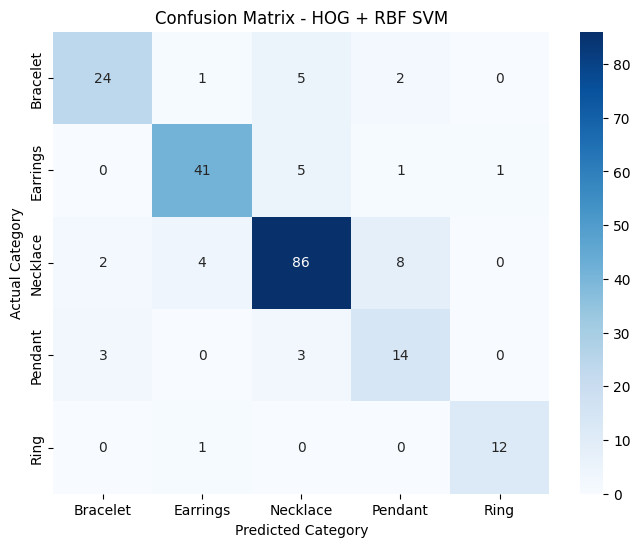

In [17]:
import seaborn as sns
# Select the best model based on cross-validation macro F1
best_model_name = "HOG + RBF SVM"
best_model = fitted_models[best_model_name]

# Predict the unseen test images
y_test_pred = best_model.predict(X_test)

# Calculate final test metrics using the integer-encoded ground truth y_test_encoded
test_accuracy = accuracy_score(y_test_encoded, y_test_pred)
test_precision = precision_score(y_test_encoded, y_test_pred, average="macro", zero_division=0)
test_recall = recall_score(y_test_encoded, y_test_pred, average="macro", zero_division=0)
test_f1 = f1_score(y_test_encoded, y_test_pred, average="macro", zero_division=0)

# Display final results
print("FINAL TEST RESULTS")
print("------------------")
print("Selected Model:", best_model_name)
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Macro Precision: {test_precision * 100:.2f}%")
print(f"Test Macro Recall: {test_recall * 100:.2f}%")
print(f"Test Macro F1: {test_f1 * 100:.2f}%")

# Show performance for each jewellery category using encoded labels
print("\nCLASSIFICATION REPORT")
print("---------------------")
print(classification_report(
    y_test_encoded,
    y_test_pred,
    target_names=class_names,
    zero_division=0
))

# Display confusion matrix using encoded labels
cm = confusion_matrix(y_test_encoded, y_test_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.title("Confusion Matrix - HOG + RBF SVM")
plt.show()

### Final Model Evaluation and Conclusion

The HOG + RBF SVM model was selected for final testing because it achieved the highest cross-validation macro F1-score of **74.36%** among the five models evaluated.

The model was evaluated using a separate test dataset containing 213 images that were not used during model training or cross-validation.

The final model achieved:
- **Test Accuracy:** 83.10%
- **Macro Precision:** 81.03%
- **Macro Recall:** 81.74%
- **Macro F1-score:** 81.19%

The classification report shows that the model performed particularly well when identifying Rings, with an F1-score of 0.92. Earrings and Necklaces both achieved an F1-score of 0.86, while Bracelets achieved 0.79.

Pendants had the lowest F1-score of 0.62, indicating that this category was more difficult for the model to classify accurately. This may be partly related to the smaller number of Pendant images available in the dataset.

Overall, the results demonstrate that HOG-based feature extraction combined with an RBF SVM can successfully classify jewellery images into five categories: Bracelet, Earrings, Necklace, Pendant, and Ring.

The project provides a working baseline for jewellery image classification. Future improvements could include collecting more images for underrepresented categories, experimenting with additional feature extraction techniques, and further optimising model parameters.